# Steel Plate Fault Classification

Quality control in a steel mill: each plate is measured (geometry, luminance statistics, indices) and labelled with one of **7 fault types** — pastry, scratches, stains, dirtiness, bumps and others. Classify the fault from the measurements so the production line can react.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

raw = download('https://archive.ics.uci.edu/static/public/198/steel+plates+faults.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.NNA')][0]
df = pd.read_csv(io.BytesIO(zf.read(name)), sep=r'\s+', header=None)
print(df.shape)
df.head(3)

(1941, 34)


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0


In [2]:
fault_names = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
y = df.iloc[:, 27:34].idxmax(axis=1).map(lambda i: fault_names[i - 27])
X = df.iloc[:, :27]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.7963
Logistic Regression accuracy: 0.7222
              precision    recall  f1-score   support

       Bumps       0.74      0.72      0.73       101
   Dirtiness       0.92      0.86      0.89        14
    K_Scatch       0.97      0.91      0.94        98
Other_Faults       0.71      0.85      0.77       168
      Pastry       0.65      0.44      0.52        39
      Stains       0.93      0.78      0.85        18
   Z_Scratch       0.98      0.83      0.90        48

    accuracy                           0.80       486
   macro avg       0.84      0.77      0.80       486
weighted avg       0.80      0.80      0.80       486



10    0.063586
4     0.059951
21    0.056688
7     0.050655
17    0.049854
13    0.049392
22    0.048288
8     0.041883
0     0.041408
1     0.040955
dtype: float64


<Axes: title={'center': 'Most informative plate measurements'}>

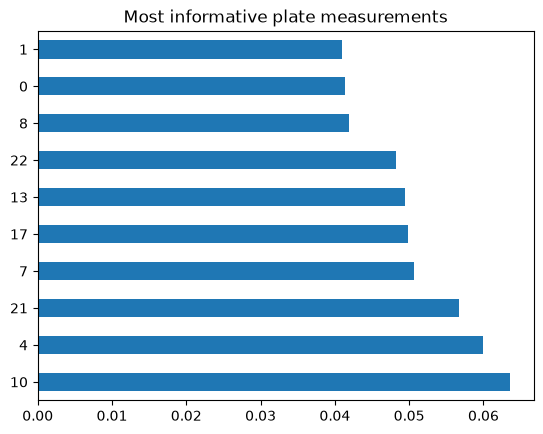

In [3]:
imp = pd.Series(rf.feature_importances_).sort_values(ascending=False)
print(imp.head(10))
imp.head(10).plot(kind='barh', title='Most informative plate measurements')